# H-N00 연결 성분 후처리 threshold 검증

원본 validation 예측은 변경하지 않고, 3D 26-connectivity component의 최소 부피 threshold를 바꾸며 양성·음성 성능을 함께 계산합니다.

- 양성 Macro Dice / Recall / Precision / 탐지율
- `<5 mL` Macro Dice / Recall / 탐지율
- 음성 case specificity / FP voxel·부피
- 새롭게 미탐지되는 작은 병변
- 안전 조건을 만족하는 threshold 자동 추천

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from scipy import ndimage
from IPython.display import display

ROOT=Path("/home/stu03/workspace/model")
DATA_ROOT=Path("/home/stu03/workspace/datasets/hemorrhage/v1/model_ready/nnunet")
FOLD=ROOT/"runs/nnunet/Dataset001_ICHBinary/nnUNetTrainerICHBaseline__ICHPlansBaselineV1__3d_fullres/fold_0"
PRED_DIR=FOLD/"validation"
GT_DIR=DATA_ROOT/"nnUNet_preprocessed/Dataset001_ICHBinary/gt_segmentations"
SPLIT=DATA_ROOT/"nnUNet_preprocessed/Dataset001_ICHBinary/splits_final.json"
OUTPUT_DIR=ROOT/"runs/comparisons/H-N00_postprocessing"; OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
THRESHOLDS_ML=[0.0,0.005,0.01,0.025,0.05,0.1,0.25]
CASES=json.loads(SPLIT.read_text(encoding="utf-8"))[0]["val"]
STRUCTURE=ndimage.generate_binary_structure(3,3)
assert len(CASES)==40 and (PRED_DIR/"summary.json").is_file()
print("cases:",len(CASES),"thresholds:",THRESHOLDS_ML)

cases: 40 thresholds: [0.0, 0.005, 0.01, 0.025, 0.05, 0.1, 0.25]


## 1. 연결 성분 필터와 지표 함수

In [2]:
def filter_components(mask,voxel_ml,threshold_ml):
    mask=np.asarray(mask,bool)
    if threshold_ml<=0 or not mask.any(): return mask.copy(),0,0
    labels,count=ndimage.label(mask,structure=STRUCTURE); sizes=np.bincount(labels.ravel())
    minimum_voxels=max(1,int(np.ceil(threshold_ml/voxel_ml)))
    remove=sizes<minimum_voxels; remove[0]=False
    result=mask.copy(); result[remove[labels]]=False
    return result,int(remove[1:].sum()),int(mask.sum()-result.sum())

def metrics(gt,pred):
    gt,pred=np.asarray(gt,bool),np.asarray(pred,bool)
    tp=int((gt&pred).sum()); fp=int((~gt&pred).sum()); fn=int((gt&~pred).sum())
    denom=2*tp+fp+fn
    return tp,fp,fn,2*tp/denom if denom else np.nan,tp/(tp+fn) if tp+fn else np.nan,tp/(tp+fp) if tp+fp else np.nan

## 2. 40 case × 모든 threshold 계산

In [3]:
rows=[]
for number,case in enumerate(CASES,1):
    pred_img=nib.load(PRED_DIR/f"{case}.nii.gz"); gt_img=nib.load(GT_DIR/f"{case}.nii.gz")
    pred=np.asarray(pred_img.dataobj)>0; gt=np.asarray(gt_img.dataobj)>0
    if pred.shape!=gt.shape: raise ValueError(f"shape mismatch: {case}")
    voxel_ml=float(np.prod(gt_img.header.get_zooms()[:3]))/1000; gt_ml=float(gt.sum())*voxel_ml; positive=bool(gt.any())
    group="negative" if not positive else "<1 mL" if gt_ml<1 else "1–5 mL" if gt_ml<5 else "5–20 mL" if gt_ml<20 else "≥20 mL"
    for threshold in THRESHOLDS_ML:
        filtered,removed_components,removed_voxels=filter_components(pred,voxel_ml,threshold)
        tp,fp,fn,dice,recall,precision=metrics(gt,filtered)
        rows.append({"case_id":case,"source":"PhysioNet" if case.startswith("PHYS_") else "BHSD","positive":positive,"gt_volume_ml":gt_ml,"volume_group":group,"threshold_ml":threshold,"dice":dice,"recall":recall,"precision":precision,"tp":tp,"fp":fp,"fn":fn,"predicted_voxels":int(filtered.sum()),"predicted_volume_ml":float(filtered.sum())*voxel_ml,"overlap_detected":tp>0,"predicted_positive":bool(filtered.any()),"removed_components":removed_components,"removed_voxels":removed_voxels})
    if number%10==0: print(f"{number}/{len(CASES)}")
per_case=pd.DataFrame(rows); display(per_case.head())

10/40
20/40
30/40
40/40


,case_id,source,positive,gt_volume_ml,volume_group,threshold_ml,dice,recall,precision,tp,fp,fn,predicted_voxels,predicted_volume_ml,overlap_detected,predicted_positive,removed_components,removed_voxels
0,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.000,0.882037,0.892540,0.871778,73232,10771,8817,84003,108.003685,True,True,0,0
1,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.005,0.882048,0.892540,0.871799,73232,10769,8817,84001,108.001114,True,True,2,2
2,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.010,0.882048,0.892540,0.871799,73232,10769,8817,84001,108.001114,True,True,2,2
3,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.025,0.882048,0.892540,0.871799,73232,10769,8817,84001,108.001114,True,True,2,2
4,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.050,0.882017,0.892369,0.871902,73218,10757,8831,83975,107.967686,True,True,3,28


## 3. 양성·작은 병변·음성 결과 요약

In [4]:
rows=[]
for threshold in THRESHOLDS_ML:
    current=per_case[per_case.threshold_ml==threshold]; positive=current[current.positive]; negative=current[~current.positive]; small=positive[positive.gt_volume_ml<5]
    rows.append({"threshold_ml":threshold,"macro_dice_positive":positive.dice.mean(),"macro_recall_positive":positive.recall.mean(),"macro_precision_positive":positive.precision.mean(),"detection_positive":positive.overlap_detected.mean(),"zero_dice_positive":int((positive.dice==0).sum()),"macro_dice_under_5ml":small.dice.mean(),"macro_recall_under_5ml":small.recall.mean(),"detection_under_5ml":small.overlap_detected.mean(),"zero_dice_under_5ml":int((small.dice==0).sum()),"case_specificity":(~negative.predicted_positive).mean(),"true_negative_cases":int((~negative.predicted_positive).sum()),"false_positive_cases":int(negative.predicted_positive.sum()),"mean_fp_voxels_negative":negative.fp.mean(),"total_fp_voxels_negative":negative.fp.sum(),"total_fp_volume_ml_negative":negative.predicted_volume_ml.sum()})
summary=pd.DataFrame(rows); base=summary.iloc[0]
summary["dice_delta"]=summary.macro_dice_positive-base.macro_dice_positive
summary["small_dice_delta"]=summary.macro_dice_under_5ml-base.macro_dice_under_5ml
summary["small_detection_delta"]=summary.detection_under_5ml-base.detection_under_5ml
formats={c:"{:.4f}" for c in ["macro_dice_positive","macro_recall_positive","macro_precision_positive","macro_dice_under_5ml","macro_recall_under_5ml","dice_delta","small_dice_delta"]}
formats.update({c:"{:.2%}" for c in ["detection_positive","detection_under_5ml","case_specificity","small_detection_delta"]})
display(summary.style.format(formats).background_gradient(subset=["macro_dice_positive","macro_dice_under_5ml","case_specificity"],cmap="YlGn"))

,threshold_ml,macro_dice_positive,macro_recall_positive,macro_precision_positive,detection_positive,zero_dice_positive,macro_dice_under_5ml,macro_recall_under_5ml,detection_under_5ml,zero_dice_under_5ml,case_specificity,true_negative_cases,false_positive_cases,mean_fp_voxels_negative,total_fp_voxels_negative,total_fp_volume_ml_negative,dice_delta,small_dice_delta,small_detection_delta
0,0.000000,0.5946,0.6212,0.6068,91.43%,3,0.3447,0.4612,72.73%,3,0.00%,0,5,2037.600000,10188,9.971592,0.0000,0.0000,0.00%
1,0.005000,0.5946,0.6212,0.6069,91.43%,3,0.3447,0.4612,72.73%,3,0.00%,0,5,2036.800000,10184,9.967556,0.0000,0.0000,0.00%
2,0.010000,0.5946,0.6211,0.6070,91.43%,3,0.3449,0.4612,72.73%,3,0.00%,0,5,2035.400000,10177,9.960493,0.0001,0.0001,0.00%
3,0.025000,0.5950,0.6210,0.6078,91.43%,3,0.3459,0.4612,72.73%,3,0.00%,0,5,2015.400000,10077,9.860322,0.0004,0.0012,0.00%
4,0.050000,0.5952,0.6189,0.6091,91.43%,3,0.3466,0.4558,72.73%,3,0.00%,0,5,1980.000000,9900,9.681732,0.0006,0.0019,0.00%
5,0.100000,0.5969,0.6186,0.6306,91.43%,3,0.3510,0.4558,72.73%,3,0.00%,0,5,1896.000000,9480,9.284082,0.0023,0.0063,0.00%
6,0.250000,0.5977,0.6114,0.6553,91.43%,3,0.3531,0.4375,72.73%,3,20.00%,1,4,1785.000000,8925,8.785880,0.0032,0.0084,0.00%


## 4. Trade-off 그래프

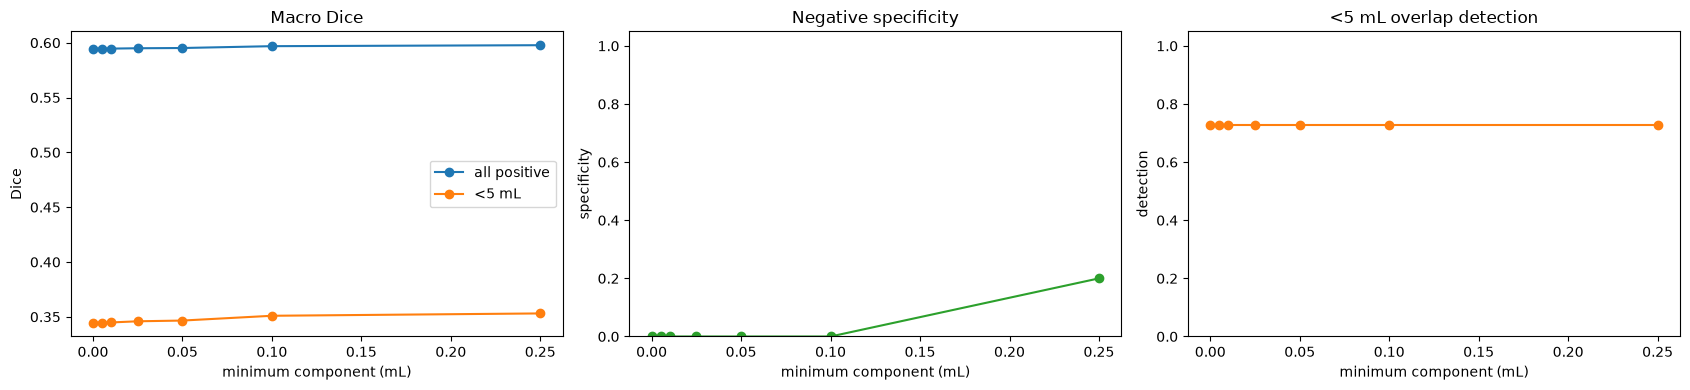

In [5]:
fig,axes=plt.subplots(1,3,figsize=(17,4))
axes[0].plot(summary.threshold_ml,summary.macro_dice_positive,"o-",label="all positive"); axes[0].plot(summary.threshold_ml,summary.macro_dice_under_5ml,"o-",label="<5 mL"); axes[0].set(title="Macro Dice",xlabel="minimum component (mL)",ylabel="Dice"); axes[0].legend()
axes[1].plot(summary.threshold_ml,summary.case_specificity,"o-",color="tab:green"); axes[1].set(title="Negative specificity",xlabel="minimum component (mL)",ylabel="specificity",ylim=(0,1.05))
axes[2].plot(summary.threshold_ml,summary.detection_under_5ml,"o-",color="tab:orange"); axes[2].set(title="<5 mL overlap detection",xlabel="minimum component (mL)",ylabel="detection",ylim=(0,1.05))
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"threshold_tradeoff.png",dpi=170); plt.show()

## 5. 안전 threshold 자동 추천

조건: 전체 양성 Macro Dice 감소 ≤ 0.01, `<5 mL` 탐지율 감소 없음. 조건 안에서 specificity가 가장 높은 값을 추천합니다.

In [5]:
MAX_DICE_DROP=0.01
candidates=summary[(summary.dice_delta>=-MAX_DICE_DROP)&(summary.small_detection_delta>=0)].copy()
if len(candidates):
    recommended=candidates.sort_values(["case_specificity","macro_dice_positive","threshold_ml"],ascending=[False,False,True]).iloc[0]
    print("recommended threshold:",recommended.threshold_ml,"mL"); display(recommended.to_frame("value"))
else:
    recommended=None; print("안전 조건을 만족하는 threshold 없음: 0 mL 유지")

recommended threshold: 0.25 mL


,value
threshold_ml,0.250000
macro_dice_positive,0.597732
macro_recall_positive,0.611375
macro_precision_positive,0.655327
detection_positive,0.914286
zero_dice_positive,3.000000
macro_dice_under_5ml,0.353095
macro_recall_under_5ml,0.437520
detection_under_5ml,0.727273
zero_dice_under_5ml,3.000000


## 6. 음성 case별 FP 변화

fp                                     predicted_volume_ml  \
threshold_ml 0.000 0.005 0.010 0.025 0.050 0.100 0.250               0.000   
case_id                                                                      
PHYS_110       237   237   237   218   218   109     0            0.243307   
PHYS_114       277   277   277   277   277   277   277            0.251086   
PHYS_119       371   371   371   358   358   309   309            0.442266   
PHYS_120      1634  1634  1634  1618  1618  1446  1150            1.297007   
PHYS_125      7669  7665  7658  7606  7429  7339  7189            7.737925   

                                  ...                                \
threshold_ml     0.005     0.010  ...     0.050     0.100     0.250   
case_id                           ...                                 
PHYS_110      0.243307  0.243307  ...  0.223801  0.111901       0.0   
PHYS_114      0.251086  0.251086  ...  0.251086  0.251086  0.251086   
PHYS_119      0.442266  0.442266  ...  0.426769  0.368357  0.368357   
PHYS_120      1.297007  1.297007  ...  1.284307   1.14778  0.912827   
PHYS_125      7.733889  7.726826  ...  7.495768  7.404959  7.253611   

             predicted_positive                                       
threshold_ml              0.000 0.005 0.010 0.025 0.050 0.100  0.250  
case_id                                                               
PHYS_110                   True  True  True  True  True  True  False  
PHYS_114                   True  True  True  True  True  True   True  
PHYS_119                   True  True  True  True  True  True   True  
PHYS_120                   True  True  True  True  True  True   True  
PHYS_125                   True  True  True  True  True  True   True  

[5 rows x 21 columns]

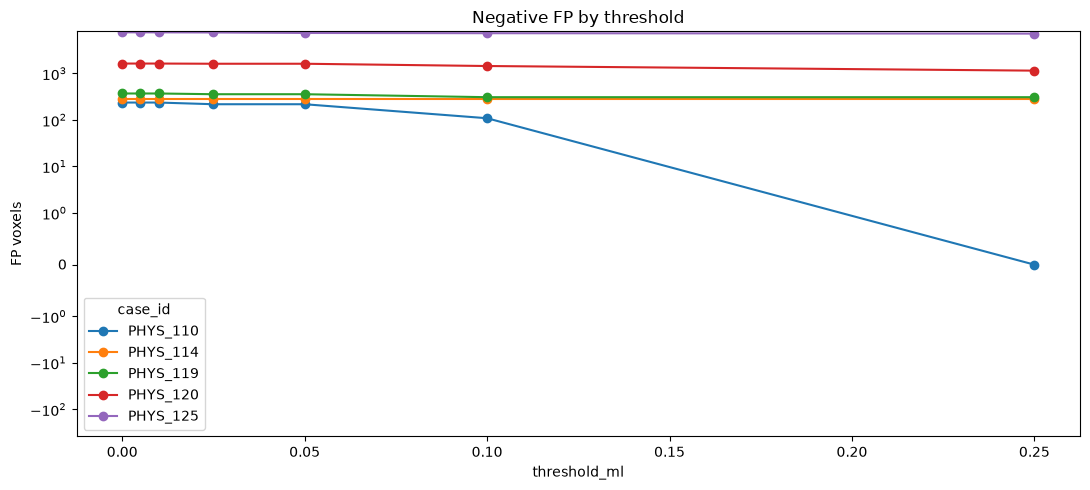

In [7]:
negative_detail=per_case[~per_case.positive].pivot(index="case_id",columns="threshold_ml",values=["fp","predicted_volume_ml","predicted_positive"])
display(negative_detail)
ax=per_case[~per_case.positive].pivot(index="threshold_ml",columns="case_id",values="fp").plot(marker="o",figsize=(11,5)); ax.set_yscale("symlog",linthresh=1); ax.set_ylabel("FP voxels"); ax.set_title("Negative FP by threshold"); plt.tight_layout(); plt.savefig(OUTPUT_DIR/"negative_fp.png",dpi=170); plt.show()

## 7. 작은 병변 개별 변화와 새 미탐지

In [6]:
small_detail=per_case[per_case.positive&(per_case.gt_volume_ml<5)].pivot(index=["case_id","source","gt_volume_ml"],columns="threshold_ml",values=["dice","recall","overlap_detected"])
display(small_detail)
base_detected=set(per_case[(per_case.threshold_ml==0)&per_case.positive&per_case.overlap_detected].case_id)
for threshold in THRESHOLDS_ML[1:]:
    detected=set(per_case[(per_case.threshold_ml==threshold)&per_case.positive&per_case.overlap_detected].case_id)
    print(f"{threshold:g} mL에서 새로 미탐지:",sorted(base_detected-detected))

dice            \
threshold_ml                                              0.000     0.005   
case_id                        source    gt_volume_ml                       
BHSD_ID_0b10cbee_ID_f91d6a7cd2 BHSD      2.676365           0.0       0.0   
BHSD_ID_41a55df8_ID_ca0abe844a BHSD      2.814655      0.446316  0.446316   
BHSD_ID_47aa2b3a_ID_95a9953aba BHSD      0.178717      0.031918  0.031918   
BHSD_ID_69e721e0_ID_a6f36605d7 BHSD      4.824170      0.783733  0.783733   
BHSD_ID_6c85adda_ID_86bc0ab248 BHSD      1.322407      0.206076  0.206076   
BHSD_ID_7db5845a_ID_0c7cd6982b BHSD      4.884798      0.539745  0.539745   
BHSD_ID_997f19cf_ID_8fc04eb1f5 BHSD      4.838135      0.580265  0.580515   
BHSD_ID_a72de500_ID_87b2b4fc60 BHSD      0.369558      0.344262  0.344262   
BHSD_ID_cdaa21cb_ID_a5f7ae30f1 BHSD      2.984998      0.859468  0.859468   
PHYS_58                        PhysioNet 0.252899           0.0       0.0   
PHYS_82                        PhysioNet 1.694899           0.0       0.0   

                                                                           \
threshold_ml                                              0.010     0.025   
case_id                        source    gt_volume_ml                       
BHSD_ID_0b10cbee_ID_f91d6a7cd2 BHSD      2.676365           0.0       0.0   
BHSD_ID_41a55df8_ID_ca0abe844a BHSD      2.814655      0.446316  0.449883   
BHSD_ID_47aa2b3a_ID_95a9953aba BHSD      0.178717      0.031918  0.031918   
BHSD_ID_69e721e0_ID_a6f36605d7 BHSD      4.824170      0.783733  0.783733   
BHSD_ID_6c85adda_ID_86bc0ab248 BHSD      1.322407       0.20627  0.206886   
BHSD_ID_7db5845a_ID_0c7cd6982b BHSD      4.884798      0.539745  0.541333   
BHSD_ID_997f19cf_ID_8fc04eb1f5 BHSD      4.838135      0.580515  0.583285   
BHSD_ID_a72de500_ID_87b2b4fc60 BHSD      0.369558      0.344262  0.344262   
BHSD_ID_cdaa21cb_ID_a5f7ae30f1 BHSD      2.984998      0.860664  0.863927   
PHYS_58                        PhysioNet 0.252899           0.0       0.0   
PHYS_82                        PhysioNet 1.694899           0.0       0.0   

                                                                           \
threshold_ml                                              0.050     0.100   
case_id                        source    gt_volume_ml                       
BHSD_ID_0b10cbee_ID_f91d6a7cd2 BHSD      2.676365           0.0       0.0   
BHSD_ID_41a55df8_ID_ca0abe844a BHSD      2.814655      0.449883  0.473205   
BHSD_ID_47aa2b3a_ID_95a9953aba BHSD      0.178717      0.028341  0.028938   
BHSD_ID_69e721e0_ID_a6f36605d7 BHSD      4.824170      0.786398  0.786398   
BHSD_ID_6c85adda_ID_86bc0ab248 BHSD      1.322407      0.208129  0.216483   
BHSD_ID_7db5845a_ID_0c7cd6982b BHSD      4.884798      0.540316  0.547744   
BHSD_ID_997f19cf_ID_8fc04eb1f5 BHSD      4.838135      0.591236  0.599584   
BHSD_ID_a72de500_ID_87b2b4fc60 BHSD      0.369558      0.344262  0.344262   
BHSD_ID_cdaa21cb_ID_a5f7ae30f1 BHSD      2.984998      0.863927  0.863927   
PHYS_58                        PhysioNet 0.252899           0.0       0.0   
PHYS_82                        PhysioNet 1.694899           0.0       0.0   

                                                                   recall  \
threshold_ml                                              0.250     0.000   
case_id                        source    gt_volume_ml                       
BHSD_ID_0b10cbee_ID_f91d6a7cd2 BHSD      2.676365           0.0       0.0   
BHSD_ID_41a55df8_ID_ca0abe844a BHSD      2.814655      0.502417    0.4801   
BHSD_ID_47aa2b3a_ID_95a9953aba BHSD      0.178717      0.030014  0.434783   
BHSD_ID_69e721e0_ID_a6f36605d7 BHSD      4.824170      0.801232   0.79867   
BHSD_ID_6c85adda_ID_86bc0ab248 BHSD      1.322407      0.170947  0.601463   
BHSD_ID_7db5845a_ID_0c7cd6982b BHSD      4.884798      0.571658  0.723541   
BHSD_ID_997f19cf_ID_8fc04eb1f5 BHSD      4.838135      0.599584  0.536009   
BHSD_ID_a72de500_ID_87b2b4fc60 BHSD      0.369558   

0.005 mL에서 새로 미탐지: []
0.01 mL에서 새로 미탐지: []
0.025 mL에서 새로 미탐지: []
0.05 mL에서 새로 미탐지: []
0.1 mL에서 새로 미탐지: []
0.25 mL에서 새로 미탐지: []


## 8. 결과 저장

In [9]:
per_case.to_csv(OUTPUT_DIR/"per_case_threshold_metrics.csv",index=False); summary.to_csv(OUTPUT_DIR/"threshold_summary.csv",index=False); negative_detail.to_csv(OUTPUT_DIR/"negative_case_detail.csv"); small_detail.to_csv(OUTPUT_DIR/"small_lesion_detail.csv")
print("saved:",OUTPUT_DIR)

saved: /home/stu03/workspace/model/runs/comparisons/H-N00_postprocessing


## 9. 선택 threshold mask 내보내기 (기본 비활성)

원본 `validation`은 절대 덮어쓰지 않습니다. 결과를 검토한 뒤 필요할 때만 `EXPORT_SELECTED=True`로 바꾸세요.

In [10]:
EXPORT_SELECTED=False
SELECTED_THRESHOLD_ML=float(recommended.threshold_ml) if recommended is not None else 0.0
if EXPORT_SELECTED:
    destination=FOLD/f"validation_postprocessed_{SELECTED_THRESHOLD_ML:g}ml"; destination.mkdir(parents=True,exist_ok=True)
    for case in CASES:
        image=nib.load(PRED_DIR/f"{case}.nii.gz"); mask=np.asarray(image.dataobj)>0; voxel_ml=float(np.prod(image.header.get_zooms()[:3]))/1000
        filtered,_,_=filter_components(mask,voxel_ml,SELECTED_THRESHOLD_ML)
        header=image.header.copy(); header.set_data_dtype(np.uint8)
        nib.save(nib.Nifti1Image(filtered.astype(np.uint8),image.affine,header),destination/f"{case}.nii.gz")
    print("exported:",destination)
else: print("내보내지 않음. 원본 예측 유지.")

내보내지 않음. 원본 예측 유지.
